In [ ]:
import os
import zipfile
import requests
from tqdm import tqdm

# 1. Setup clean storage path structures
# We keep images in working directory so YOLO can find them, but use /kaggle/tmp/ for the massive zip
OUTPUT_DIR = "/kaggle/working/r2ppe_dataset/images"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Moving the heavy zip location to the hidden tmp folder pool
os.makedirs("/kaggle/tmp", exist_ok=True)
ZIP_PATH = "/kaggle/tmp/temp_images.zip"

ZIP_URL = "https://zenodo.org/records/13851664/files/images.zip?download=1"

# 2. Download the file safely to the tmp folder pool
print("Downloading R2PPE images straight to Kaggle Temp Storage...")
response = requests.get(ZIP_URL, stream=True)
total_size = int(response.headers.get('content-length', 0))

with open(ZIP_PATH, "wb") as f, tqdm(
    total=total_size, unit='B', unit_scale=True, desc="Zenodo Transfer"
) as bar:
    for chunk in response.iter_content(chunk_size=65536): # Increased chunk size for faster download
        if chunk:
            f.write(chunk)
            bar.update(len(chunk))

print("\nDownload complete! Beginning smart 20% sample extraction...")

# 3. Open archive and extract only a specific slice to stay under memory limits
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    all_files = [f for f in zip_ref.namelist() if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    all_files.sort() 
    
    # Take every 5th image (Extracts exactly 20% of the dataset)
    target_subset = all_files[::5]
    print(f"Extracting {len(target_subset)} images out of {len(all_files)} total available frames...")
    
    for file in tqdm(target_subset, desc="Extracting Samples"):
        filename = os.path.basename(file)
        if filename:
            source = zip_ref.open(file)
            target_path = os.path.join(OUTPUT_DIR, filename)
            with open(target_path, "wb") as dest:
                dest.write(source.read())

# 4. CRITICAL STORAGE HYGIENE: Wipe out the temp zip file from the disk completely
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)
    print("\n Cleaned up temporary zip archive file completely.")

print(f"Verification Check: {len(os.listdir(OUTPUT_DIR))} images successfully populated in {OUTPUT_DIR}")

In [1]:
!pip install ultralytics -q
print("working...")

import os
import json
import shutil
import random
from pathlib import Path

# Setup paths based on your Kaggle configurations
ANNOTATIONS_DIR = "/kaggle/input/datasets/khadijasaeeddd/combinedannotations"
IMAGES_SRC = "/kaggle/working/r2ppe_dataset/images"

# Automatically locate the json file inside the annotations folder
json_files = [f for f in os.listdir(ANNOTATIONS_DIR) if f.endswith('.json')]
if not json_files:
    raise FileNotFoundError("Could not find the JSON annotation file inside the specified directory.")
ANNOTATIONS_JSON = os.path.join(ANNOTATIONS_DIR, json_files[0])

# Define target YOLO framework architecture folders
WORKING_DIR = Path("/kaggle/working/r2ppe_yolo")
for split in ['train', 'val']:
    (WORKING_DIR / split / 'images').mkdir(parents=True, exist_ok=True)
    (WORKING_DIR / split / 'labels').mkdir(parents=True, exist_ok=True)

print(f"Using annotation file: {ANNOTATIONS_JSON}")
print(f"Verified source images found: {len(os.listdir(IMAGES_SRC))}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 86.9 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires n

In [2]:
with open(ANNOTATIONS_JSON, 'r') as f:
    coco_data = json.load(f)

# Map image specifications from COCO arrays
image_map = {img['id']: img['file_name'] for img in coco_data['images']}
image_dims = {img['id']: (img['width'], img['height']) for img in coco_data['images']}
cat_id_to_yolo_idx = {cat['id']: idx for idx, cat in enumerate(coco_data['categories'])}
class_names_map = {idx: cat['name'] for idx, cat in enumerate(coco_data['categories'])}

# Gather images that exist in your local directory
available_images = os.listdir(IMAGES_SRC)
available_basenames = set(available_images)

# Filter matching entries
valid_image_ids = [img_id for img_id, f_name in image_map.items() if f_name in available_basenames]

# Create an 80:20 Train/Validation split rule
random.seed(42)
random.shuffle(valid_image_ids)
split_idx = int(len(valid_image_ids) * 0.8)
train_ids = set(valid_image_ids[:split_idx])

print(f"Pairing complete. Found {len(valid_image_ids)} matching images. Splitting: {len(train_ids)} Train, {len(valid_image_ids) - len(train_ids)} Val.")

# Convert absolute COCO values to normalized YOLO parameters [class, x_center, y_center, w, h]
for ann in coco_data['annotations']:
    img_id = ann['image_id']
    if img_id not in valid_image_ids:
        continue
        
    file_name = image_map[img_id]
    target_split = 'train' if img_id in train_ids else 'val'
    
    img_w, img_h = image_dims[img_id]
    xmin, ymin, bw, bh = ann['bbox'] # Absolute top-left coordinates
    
    # Mathematical normalization mapping
    x_center = (xmin + bw / 2) / img_w
    y_center = (ymin + bh / 2) / img_h
    norm_bw = bw / img_w
    norm_bh = bh / img_h
    
    yolo_class_id = cat_id_to_yolo_idx[ann['category_id']]
    
    txt_name = os.path.splitext(file_name)[0] + ".txt"
    dest_txt_path = WORKING_DIR / target_split / 'labels' / txt_name
    
    with open(dest_txt_path, "a") as lbl_file:
        lbl_file.write(f"{yolo_class_id} {x_center:.6f} {y_center:.6f} {norm_bw:.6f} {norm_bh:.6f}\n")

# Move images to their respective split directories
for img_id in valid_image_ids:
    file_name = image_map[img_id]
    target_split = 'train' if img_id in train_ids else 'val'
    shutil.copy(os.path.join(IMAGES_SRC, file_name), WORKING_DIR / target_split / 'images' / file_name)

print("YOLO text coordinate labels generated and split processing successfully completed.")

Pairing complete. Found 274 matching images. Splitting: 219 Train, 55 Val.
YOLO text coordinate labels generated and split processing successfully completed.


In [3]:
import yaml

yaml_config = {
    'path': str(WORKING_DIR),
    'train': 'train/images',
    'val': 'val/images',
    'names': class_names_map
}

yaml_path = "/kaggle/working/r2ppe_config.yaml"
with open(yaml_path, 'w') as f:
    yaml.dump(yaml_config, f, default_flow_style=False)

print(f"YOLO configuration dataset parameters written to: {yaml_path}")

YOLO configuration dataset parameters written to: /kaggle/working/r2ppe_config.yaml


In [4]:
from ultralytics import YOLO

# Load an optimized pre-trained nano framework model
model = YOLO("yolov8n.pt")

# Execute fine-tuning using the T4 GPU engine acceleration
results = model.train(
    data=yaml_path,
    epochs=20,
    imgsz=640,
    batch=16,
    device=0, # Active T4 GPU assignment
    workers=2
)
print("Model fine-tuning sequence successful!")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/r2ppe_config.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, 

Locating training performance curves...


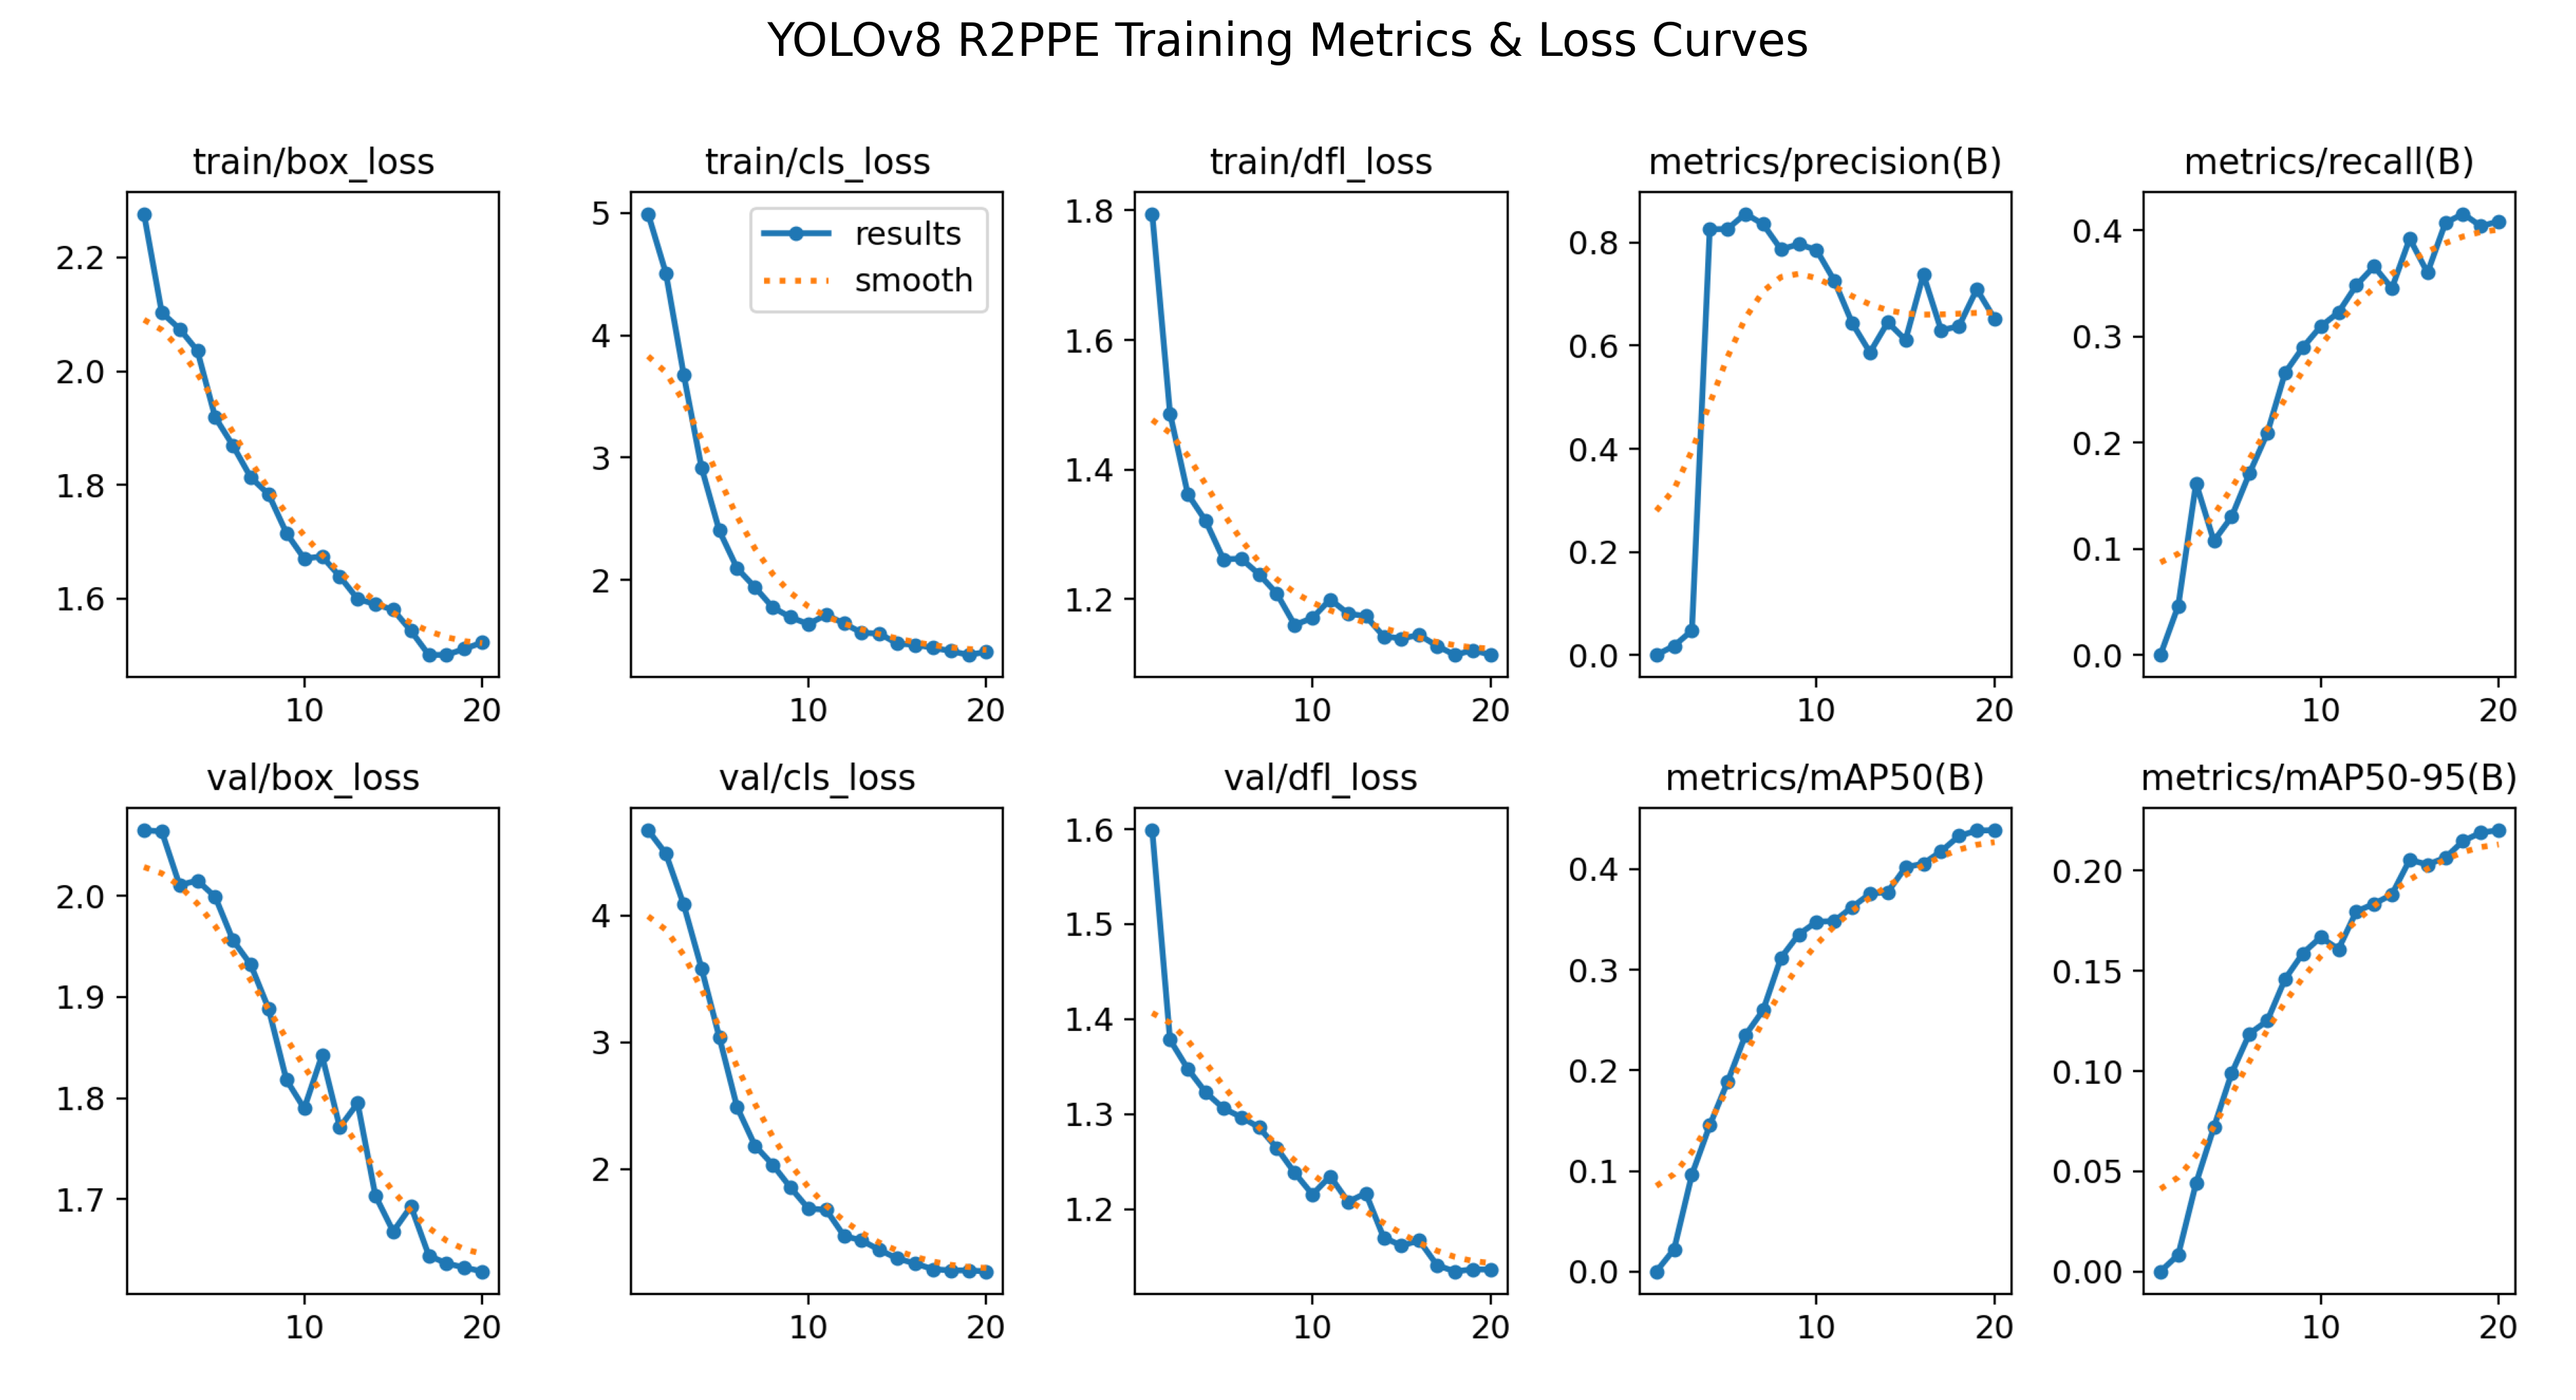

In [5]:
import os
import cv2
import matplotlib.pyplot as plt

# The path where YOLO automatically saved your custom training graphs
results_graph_path = "/kaggle/working/runs/detect/train/results.png"

if os.path.exists(results_graph_path):
    print("Locating training performance curves...")
    # Load and display the generated metrics chart
    img = cv2.imread(results_graph_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(16, 12), dpi=300)
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title("YOLOv8 R2PPE Training Metrics & Loss Curves", fontsize=16, pad=20)
    plt.show()
else:
    print("Could not find results.png. Let's look for alternative saved charts:")
    # Fallback: List available files in the directory to check what was generated
    train_dir = "/kaggle/working/runs/detect/train/"
    if os.path.exists(train_dir):
        print(os.listdir(train_dir))

In [6]:
import os
import glob
from ultralytics import YOLO

def calculate_test_set_accuracy(model_weights="/kaggle/working/runs/detect/train/weights/best.pt"):
    print("Initializing Test Set Evaluation Pipeline...")
    predictor = YOLO(model_weights)
    
    # Paths to your unseen validation/test split
    val_images_path = "/kaggle/working/r2ppe_yolo/val/images"
    val_labels_path = "/kaggle/working/r2ppe_yolo/val/labels"
    
    image_files = glob.glob(os.path.join(val_images_path, "*.*"))
    if not image_files:
        print("Error: No test images found.")
        return
        
    names_dict = predictor.names
    NON_ADHERENCE_FLAGS = ['absent', 'incomplete', '_ma', '_mi', '_ga', '_gi', '_ea', '_fi', '_ha']
    
    correct_predictions = 0
    total_images = 0
    
    # Track metrics for a system-level Confusion Matrix
    tp, fp, fn, tn = 0, 0, 0, 0 
    
    for img_path in image_files:
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        label_path = os.path.join(val_labels_path, base_name + ".txt")
        
        if not os.path.exists(label_path):
            continue # Skip if no ground truth annotation exists for comparison
            
        # 1. Determine True Ground Truth from the text label file
        has_true_violation = False
        with open(label_path, 'r') as f:
            for line in f.readlines():
                class_id = int(line.split()[0])
                class_name = names_dict[class_id].lower()
                if any(flag in class_name for flag in NON_ADHERENCE_FLAGS):
                    has_true_violation = True
                    break
        
        actual_status = "NON-ADHERENT" if has_true_violation else "ADHERENT"
        
        # 2. Get Model System Prediction
        outputs = predictor.predict(source=img_path, conf=0.25, verbose=False)
        predicted_violation = False
        
        for r in outputs:
            for box in r.boxes:
                pred_class_id = int(box.cls.item())
                pred_class_name = names_dict[pred_class_id].lower()
                if any(flag in pred_class_name for flag in NON_ADHERENCE_FLAGS):
                    predicted_violation = True
                    break
                    
        predicted_status = "NON-ADHERENT" if predicted_violation else "ADHERENT"
        
        # 3. Compare and Accumulate Metrics
        total_images += 1
        if predicted_status == actual_status:
            correct_predictions += 1
            if actual_status == "ADHERENT": tn += 1
            else: tp += 1
        else:
            if actual_status == "ADHERENT" and predicted_status == "NON-ADHERENT": fp += 1
            else: fn += 1

    # Calculate final pipeline metrics
    system_accuracy = (correct_predictions / total_images) * 100 if total_images > 0 else 0
    
    print("\n" + "="*40)
    print("       FINAL SYSTEM EVALUATION REPORT      ")
    print("="*40)
    print(f"Total Unseen Test Images Evaluated: {total_images}")
    print(f"Correct System Classifications   : {correct_predictions}")
    print(f"Overall Pipeline Accuracy        : {system_accuracy:.2f}%")
    print("-" * 40)
    print("SYSTEM CONFUSION MATRIX:")
    print(f"  True Positives  (Correctly flagged Non-Adherent): {tp}")
    print(f"  True Negatives  (Correctly flagged Adherent)    : {tn}")
    print(f"  False Positives (Safe doctors falsely flagged)  : {fp}")
    print(f"  False Negatives (Missed safety violations!)    : {fn}")
    print("="*40)

# Run the accuracy verification
calculate_test_set_accuracy()

Initializing Test Set Evaluation Pipeline...

       FINAL SYSTEM EVALUATION REPORT      
Total Unseen Test Images Evaluated: 55
Correct System Classifications   : 48
Overall Pipeline Accuracy        : 87.27%
----------------------------------------
SYSTEM CONFUSION MATRIX:
  True Positives  (Correctly flagged Non-Adherent): 48
  True Negatives  (Correctly flagged Adherent)    : 0
  False Positives (Safe doctors falsely flagged)  : 0
  False Negatives (Missed safety violations!)    : 7


In [19]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

def classify_and_segment_single_image(custom_image_path, model_weights="/kaggle/working/runs/detect/train/weights/best.pt"):
    if not os.path.isfile(custom_image_path):
        print(f"Error: '{custom_image_path}' is either a folder directory or does not exist. Please provide a direct image file path.")
        return

    # 1. Setup Models & Parameters
    predictor = YOLO(model_weights)
    names_dict = predictor.names
    
    # 2. Run Inference Pass
    outputs = predictor.predict(source=custom_image_path, conf=0.25, verbose=False)
    
    img = cv2.imread(custom_image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    segmentation_overlay = np.zeros_like(img_rgb, dtype=np.uint8)
    
    detected_elements = []
    
    # First pass: Gather all detected items in the scene
    for r in outputs:
        for box in r.boxes:
            cls_id = int(box.cls.item())
            lbl_name = names_dict[cls_id]
            detected_elements.append(lbl_name.lower())
            
            # Color-coding bounding regions for pseudo-segmentation visualization
            bbox = box.xyxy[0].cpu().numpy().astype(int)
            color = np.random.randint(50, 255, size=(3,), dtype=np.uint8).tolist()
            cv2.rectangle(segmentation_overlay, (bbox[0], bbox[1]), (bbox[2], bbox[3]), color, -1)

    if len(detected_elements) == 0:
        print("Inspection Log: No clinical targets or equipment detected in this frame.")
        return

    # 3. CRITICAL CUSTOM LOGIC MODIFICATION
    # Check if ANY valid complete mask type is present
    has_mask = any(('mask' in item or '_rc' in item or '_nc' in item) and 'absent' not in item and 'incomplete' not in item for item in detected_elements)
    
    is_compliant = True
    flagged_violations = []

    # Define base non-adherence flags
    BASE_FLAGS = ['absent', 'incomplete', '_ma', '_mi', '_ga', '_gi', '_ea', '_ha']

    for item in detected_elements:
        # If they have a mask, completely IGNORE face shield non-adherence warnings!
        if has_mask and ('_fi' in item or 'face_shield' in item):
            continue
            
        # Otherwise, flag standard violations or face shield issues if NO mask is present
        if any(flag in item for flag in BASE_FLAGS) or ('_fi' in item and not has_mask):
            is_compliant = False
            flagged_violations.append(item)

    verdict = "FULLY ADHERENT" if is_compliant else "NON-COMPLIANT"
    blended_output = cv2.addWeighted(img_rgb, 0.7, segmentation_overlay, 0.3, 0)
    
    # Print clean text outputs
    print(f"\n--- INTERACTIVE INSPECTION REPORT (UPDATED RULES) ---")
    print(f"Target File : {os.path.basename(custom_image_path)}")
    print(f"Spotted Gear: {detected_elements}")
    print(f"Final System Compliance Status: [{verdict}]")
    if has_mask and not is_compliant:
        print(" Note: Face shield omission skipped due to active Mask protection alignment.")
    if flagged_violations:
        print(f"Reason(s)   : Safety breakdown via {flagged_violations}")
    print("-" * 55)

    # Plot results side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(img_rgb)
    axes[0].set_title("Original Uploaded Image")
    axes[0].axis('off')
    
    axes[1].imshow(blended_output)
    axes[1].set_title(f"Segmented Analysis (Verdict: {verdict})")
    axes[1].axis('off')
    plt.show()


--- INTERACTIVE INSPECTION REPORT (UPDATED RULES) ---
Target File : bed_sim_n95_305.png
Spotted Gear: ['glove_absent_ha', 'glove_absent_ha', 'glove_absent_ha', 'head', 'head', 'glove_absent_ha', 'glove_absent_ha']
Final System Compliance Status: [NON-COMPLIANT]
Reason(s)   : Safety breakdown via ['glove_absent_ha', 'glove_absent_ha', 'glove_absent_ha', 'glove_absent_ha', 'glove_absent_ha']
-------------------------------------------------------


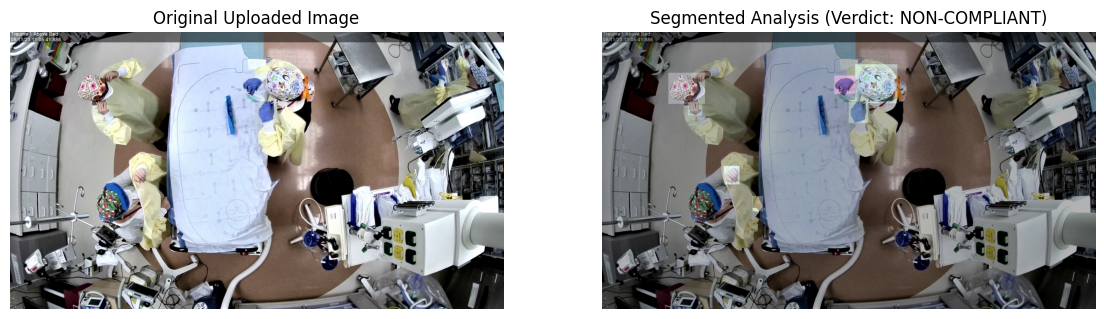

In [21]:
classify_and_segment_single_image(
    custom_image_path="/kaggle/input/datasets/khadijasaeeddd/testimage/bed_sim_n95_305.png", 
    model_weights="/kaggle/working/runs/detect/train/weights/best.pt"
)


--- INTERACTIVE INSPECTION REPORT (UPDATED RULES) ---
Target File : TestImage2.jpg
Spotted Gear: ['head', 'face_shield_incomplete_fi', 'head']
Final System Compliance Status: [NON-COMPLIANT]
Reason(s)   : Safety breakdown via ['face_shield_incomplete_fi']
-------------------------------------------------------


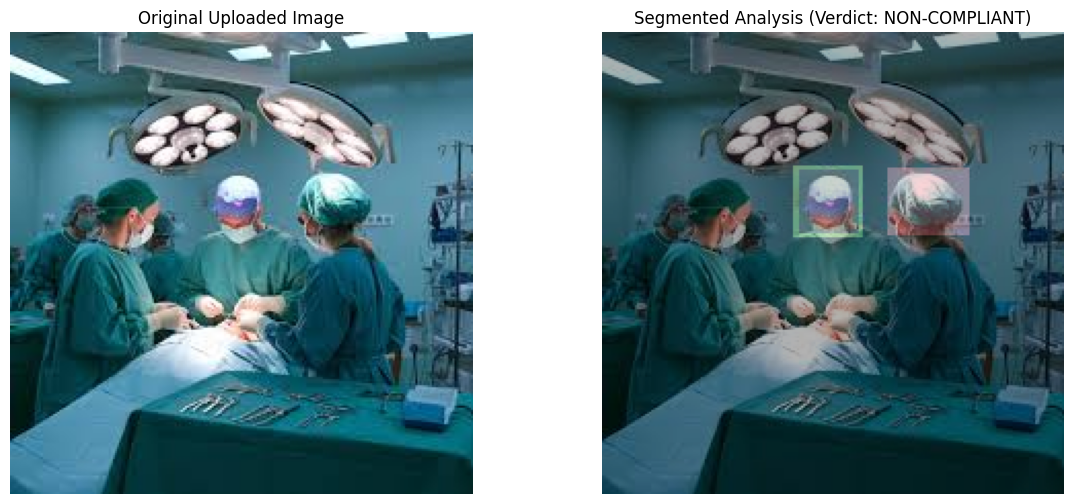

In [20]:
classify_and_segment_single_image(
    custom_image_path="/kaggle/input/datasets/khadijasaeeddd/testimage2/TestImage2.jpg", 
    model_weights="/kaggle/working/runs/detect/train/weights/best.pt"
)

  Preparing metadata (setup.py) ... done

--- INSTANCE SEGMENTATION & COMPLIANCE REPORT ---
Target File : bed_sim_n95_305.png
Spotted Gear: ['glove_absent_ha', 'glove_absent_ha', 'glove_absent_ha', 'head', 'head', 'glove_absent_ha', 'glove_absent_ha']
Final System Compliance Status: [NON-COMPLIANT]
Reason(s)   : Safety breakdown via ['glove_absent_ha']
--------------------------------------------------


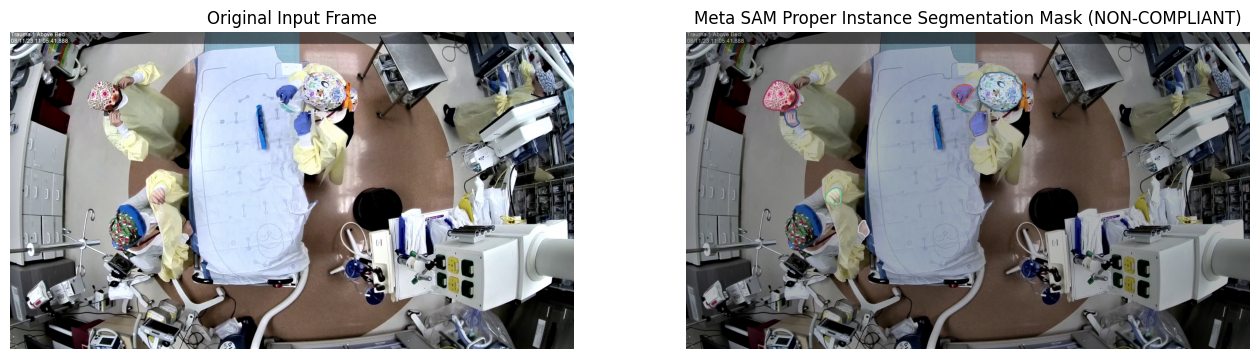

In [24]:
# 1. Install Meta's Segment Anything library quietly
!pip install git+https://github.com/facebookresearch/segment-anything.git -q

import os
import cv2
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from segment_anything import sam_model_registry, SamPredictor

# 2. Download the official lightweight SAM model checkpoint if not present
SAM_CHECKPOINT = "/kaggle/working/sam_vit_b_01ec64.pth"
if not os.path.exists(SAM_CHECKPOINT):
    print("Downloading Meta SAM weights (this will take about a minute)...")
    url = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"
    urllib.request.urlretrieve(url, SAM_CHECKPOINT)
    print("SAM Weights downloaded successfully.")

def classify_and_properly_segment_image(custom_image_path, model_weights="/kaggle/working/runs/detect/train/weights/best.pt"):
    if not os.path.isfile(custom_image_path):
        print(f"Error: '{custom_image_path}' is not a valid file path.")
        return

    # 1. Initialize YOLOv8 Detector and SAM Segmenter
    yolo_predictor = YOLO(model_weights)
    names_dict = yolo_predictor.names
    
    sam_model = sam_model_registry["vit_b"](checkpoint=SAM_CHECKPOINT)
    sam_model.to(device="cuda")  # Leverage your active T4 GPU
    sam_predictor = SamPredictor(sam_model)
    
    # 2. Run YOLOv8 Multi-Class Inference Pass
    outputs = yolo_predictor.predict(source=custom_image_path, conf=0.25, verbose=False)
    
    img = cv2.imread(custom_image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Initialize SAM with the loaded image
    sam_predictor.set_image(img_rgb)
    
    # Create empty canvases for masks and colorful outlines
    mask_overlay = np.zeros_like(img_rgb, dtype=np.uint8)
    contour_overlay = img_rgb.copy()
    
    detected_elements = []
    yolo_boxes = []
    
    # Gather coordinates
    for r in outputs:
        for box in r.boxes:
            cls_id = int(box.cls.item())
            lbl_name = names_dict[cls_id].lower()
            detected_elements.append(lbl_name)
            
            # Save bounding box coordinates [xmin, ymin, xmax, ymax]
            bbox = box.xyxy[0].cpu().numpy()
            yolo_boxes.append((bbox, lbl_name))

    if not detected_elements:
        print("Inspection Log: No targets detected in this frame.")
        return

    # 3. Apply Custom Rule Engine Logic (Mask compliance bypass)
    has_mask = any(('mask' in item or '_rc' in item or '_nc' in item) and 'absent' not in item and 'incomplete' not in item for item in detected_elements)
    
    is_compliant = True
    flagged_violations = []
    BASE_FLAGS = ['absent', 'incomplete', '_ma', '_mi', '_ga', '_gi', '_ea', '_ha']

    # 4. Generate Proper Segmentation Masks Using SAM
    for bbox, lbl_name in yolo_boxes:
        # Evaluate compliance status strings
        if has_mask and ('_fi' in lbl_name or 'face_shield' in lbl_name):
            pass  # Skip violation flag
        elif any(flag in lbl_name for flag in BASE_FLAGS) or ('_fi' in lbl_name and not has_mask):
            is_compliant = False
            if lbl_name not in flagged_violations:
                flagged_violations.append(lbl_name)

        # Pass the YOLO bounding box directly as a structural prompt to SAM
        masks, scores, _ = sam_predictor.predict(
            box=bbox,
            multimask_output=False
        )
        
        # Isolate the binary mask array
        actual_mask = masks[0]
        
        # Generate a distinct bright random color for this specific segmented object
        color = np.random.randint(60, 255, size=(3,), dtype=np.uint8).tolist()
        
        # Fill the mask with solid color translucent opacity
        mask_overlay[actual_mask] = color
        
        # Draw precise pixel-level boundaries around the segmentation mask edges
        contours, _ = cv2.findContours(actual_mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(contour_overlay, contours, -1, color, 3)

    # Blend the solid mask layer back into the outlined contours image matrix
    final_segmented_image = cv2.addWeighted(contour_overlay, 0.7, mask_overlay, 0.3, 0)
    verdict = "FULLY ADHERENT" if is_compliant else "NON-COMPLIANT"

    # 5. Render Metric Reports
    print(f"\n--- INSTANCE SEGMENTATION & COMPLIANCE REPORT ---")
    print(f"Target File : {os.path.basename(custom_image_path)}")
    print(f"Spotted Gear: {detected_elements}")
    print(f"Final System Compliance Status: [{verdict}]")
    if flagged_violations:
        print(f"Reason(s)   : Safety breakdown via {flagged_violations}")
    print("-" * 50)

    # Plot results side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(img_rgb)
    axes[0].set_title("Original Input Frame")
    axes[0].axis('off')
    
    axes[1].imshow(final_segmented_image)
    axes[1].set_title(f"Meta SAM Proper Instance Segmentation Mask ({verdict})")
    axes[1].axis('off')
    plt.show()

# 6. Execute Example Call
# Replace this path string with your target test image file path
classify_and_properly_segment_image(
    custom_image_path="/kaggle/input/datasets/khadijasaeeddd/testimage/bed_sim_n95_305.png",
    model_weights="/kaggle/working/runs/detect/train/weights/best.pt"
)


--- INSTANCE SEGMENTATION & COMPLIANCE REPORT ---
Target File : clinical_simulation_1_25.png
Spotted Gear: ['head', 'head', 'head', 'gown_absent_ga', 'gown_incomplete_gi', 'glove_absent_ha', 'head']
Final System Compliance Status: [NON-COMPLIANT]
Reason(s)   : Safety breakdown via ['gown_absent_ga', 'gown_incomplete_gi', 'glove_absent_ha']
--------------------------------------------------


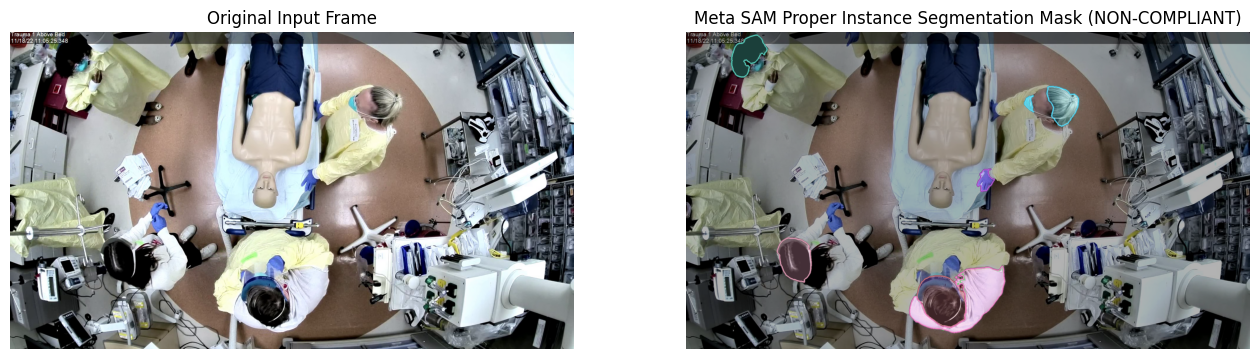

In [27]:
classify_and_properly_segment_image(
    custom_image_path="/kaggle/input/datasets/khadijasaeeddd/testimages3/clinical_simulation_1_25.png",
    model_weights="/kaggle/working/runs/detect/train/weights/best.pt"
)

In [25]:
import shutil
from IPython.display import FileLink
import os

# Folder containing all training results, graphs, and weights
results_dir = "/kaggle/working/runs/detect/train"
output_zip = "/kaggle/working/yolov8_r2ppe_training_results"

if os.path.exists(results_dir):
    print("Compresing training folder...")
    # Creates a zip file named yolov8_r2ppe_training_results.zip
    shutil.make_archive(output_zip, 'zip', results_dir)
    
    print("\nClick the link below to download your complete project results zip:")
    display(FileLink(output_zip + ".zip"))
else:
    print("Training directory not found.")

Compresing training folder...

Click the link below to download your complete project results zip:


/kaggle/working/yolov8_r2ppe_training_results.zip